# A3 – Detección de fugas de ingresos

El enunciado pide cuatro cosas para A3:

1. El patrón de devoluciones: si hay productos, categorías o segmentos con tasas anómalas, y si hay clientes que devuelven una y otra vez.
2. Cruzar el CRM con las compras posteriores: ¿los clientes con quejas no resueltas compran menos después?
3. Los clientes en riesgo de fuga (*churn*): definir una medida de inactividad y encontrar el segmento de mayor valor en riesgo.
4. El impacto económico de las fugas, expresado en ingresos perdidos proyectados a 6 meses.

Usamos los datos limpios de A1 (`cargar_limpio`). Los montos están en unidades monetarias (u. m.).

**Sobre el segmento:** el segmento del archivo es una franja del número de compras de los 24 meses (A1.4). Lo usamos para describir (por ejemplo, la tasa de devolución por segmento), pero no para predecir. La probabilidad de que un cliente vuelva se estima solo con lo que se sabía de él en la fecha de corte. Las decisiones están explicadas en `DECISIONES.md` (A3.1 a A3.5).

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from src.carga import cargar_limpio, RAIZ, DIAS_INACTIVO, MOTIVOS_PERDIDA

d = cargar_limpio()
cli = d["clientes"]
trx = d["transacciones"].merge(cli[["cliente_id", "segmento"]], on="cliente_id")
dev = d["devoluciones"]
crm = d["interacciones_crm"]
FIN = trx.fecha.max()
FIG = RAIZ / "figures"
rng = np.random.default_rng(2026)

# Colores (paleta de referencia de la guía de visualización)
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
TEXTO, TEXTO_2, FONDO = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def miles(x):
    # 1.234 en vez de 1,234
    return f"{x:,.0f}".replace(",", ".")

print("Datos del", trx.fecha.min().date(), "al", FIN.date())

Datos del 2023-01-01 al 2024-12-31


## 1. Devoluciones: ¿dónde se devuelve más de lo normal?

Comparamos la tasa de devolución (ventas devueltas / ventas) de cada grupo con la tasa global.

**Cuándo decimos que una tasa es anómala (A3.1):** cuando la diferencia con la tasa de referencia no se explica por azar. Usamos una prueba binomial y, como comparamos muchos grupos a la vez (318 productos), corregimos con Benjamini-Hochberg. Sin esa corrección, de 318 productos saldrían unos 16 "anómalos" por pura casualidad. También mostramos el intervalo de confianza del 95% (Wilson) de cada tasa.

In [2]:
tasa_global = trx.devuelta.mean()
print(f"Tasa global de devolución: {tasa_global:.1%} ({miles(trx.devuelta.sum())} de {miles(len(trx))} ventas)")
print("Por semestre:", (trx.groupby(trx.fecha.dt.year.astype(str) + "-S" + (1 + (trx.fecha.dt.month > 6)).astype(str))
                        .devuelta.mean() * 100).round(1).to_dict())

def tasas(col, ref=None, n_min=0):
    # ref: tasa con la que se compara cada grupo (por defecto, la global)
    g = trx.groupby(col).devuelta.agg(ventas="size", devueltas="sum")
    g = g[g.ventas >= n_min]
    g["tasa %"] = 100 * g.devueltas / g.ventas
    lo, hi = proportion_confint(g.devueltas, g.ventas, method="wilson")
    g["IC 95%"] = [f"{100 * a:.1f} – {100 * b:.1f}" for a, b in zip(lo, hi)]
    r = pd.Series(tasa_global, index=g.index) if ref is None else ref
    g["p"] = [stats.binomtest(int(k), int(n), p).pvalue for k, n, p in zip(g.devueltas, g.ventas, r)]
    g["anómala"] = multipletests(g.p, method="fdr_bh")[0]
    return g.sort_values("tasa %", ascending=False)

for col in ["categoria", "segmento", "canal", "metodo_pago"]:
    print()
    print(tasas(col).round({"tasa %": 1, "p": 4}).to_string())

Tasa global de devolución: 13.4% (6.724 de 50.000 ventas)
Por semestre: {'2023-S1': 13.4, '2023-S2': 13.4, '2024-S1': 13.3, '2024-S2': 13.6}

                     ventas  devueltas  tasa %       IC 95%    p  anómala
categoria                                                                
Ropa_y_Calzado         8311       1810    21.8  20.9 – 22.7  0.0     True
Electrónica            8419       1486    17.7  16.9 – 18.5  0.0     True
Deportes               8311        887    10.7  10.0 – 11.4  0.0     True
Belleza_y_Salud        8287        878    10.6  10.0 – 11.3  0.0     True
Alimentos_y_Bebidas    8317        845    10.2   9.5 – 10.8  0.0     True
Hogar_y_Deco           8355        818     9.8   9.2 – 10.4  0.0     True

            ventas  devueltas  tasa %       IC 95%       p  anómala
segmento                                                           
Esporádico    7792       1065    13.7  12.9 – 14.4  0.5724    False
Frecuente    25458       3436    13.5  13.1 – 13.9  0.8184   

Solo las **categorías** se salen de lo normal: Ropa y Calzado y Electrónica devuelven mucho más que la media, y las otras cuatro, menos. Ni el segmento, ni el canal, ni el medio de pago cambian la tasa.

Ahora bajamos a subcategorías y productos. La pregunta importante es si hay productos raros **dentro de su categoría**: un pantalón que se devuelve al 22% no es raro si toda la ropa se devuelve al 22%.

In [3]:
prod_global = tasas("producto_id")
print(f"Productos anómalos comparados con la tasa global: {prod_global.anómala.sum()} de {len(prod_global)}")
print("  ¿De qué categoría son?", trx.drop_duplicates("producto_id").set_index("producto_id")
      .categoria.reindex(prod_global[prod_global.anómala].index).value_counts().to_dict())

# Misma prueba, pero comparando cada producto y subcategoría con la tasa de su propia categoría
tasa_cat = trx.groupby("categoria").devuelta.mean()
ref_prod = trx.drop_duplicates("producto_id").set_index("producto_id").categoria.map(tasa_cat)
prod_cat = tasas("producto_id", ref=ref_prod.sort_index())
ref_sub = trx.drop_duplicates("subcategoria").set_index("subcategoria").categoria.map(tasa_cat)
sub_cat = tasas("subcategoria", ref=ref_sub.sort_index())
print(f"Productos anómalos comparados con su categoría: {prod_cat.anómala.sum()} de {len(prod_cat)} "
      f"(p más bajo: {prod_cat.p.min():.4f})")
print(f"Subcategorías anómalas comparadas con su categoría: {sub_cat.anómala.sum()} de {len(sub_cat)}")
print("Ventas por producto (mín / mediana / máx):", prod_cat.ventas.min(), prod_cat.ventas.median(), prod_cat.ventas.max())

Productos anómalos comparados con la tasa global: 51 de 318
  ¿De qué categoría son? {'Ropa_y_Calzado': 32, 'Electrónica': 6, 'Deportes': 4, 'Hogar_y_Deco': 4, 'Alimentos_y_Bebidas': 3, 'Belleza_y_Salud': 2}


Productos anómalos comparados con su categoría: 0 de 318 (p más bajo: 0.0035)
Subcategorías anómalas comparadas con su categoría: 0 de 24
Ventas por producto (mín / mediana / máx): 115 158.0 190


Los 51 productos "anómalos" son solo el reflejo de su categoría: al compararlos con su propia categoría, no queda ninguno. Lo mismo pasa con las subcategorías. **El problema está en la categoría completa, no en productos concretos.** Todos los productos tienen más de 100 ventas, así que no es falta de datos.

¿Por qué devuelven tanto Ropa y Calzado y Electrónica? Miramos los motivos.

In [4]:
motivos = pd.crosstab(dev.categoria, dev.motivo)
pct = (100 * motivos.div(motivos.sum(axis=1), axis=0)).round(1)
print("% de las devoluciones de cada categoría, por motivo:")
print(pct.to_string())

# Tasa de devolución por motivo: devoluciones por cada 100 ventas de la categoría
ventas_cat = trx.groupby("categoria").size()
por_100 = (100 * motivos.div(ventas_cat, axis=0)).round(2)
print("\nDevoluciones por cada 100 ventas, por motivo:")
print(por_100.to_string())

resto = ~por_100.index.isin(["Ropa_y_Calzado", "Electrónica"])
print("\nExceso de Ropa y Electrónica sobre la media de las otras 4 categorías (puntos por cada 100 ventas):")
print((por_100.loc[["Ropa_y_Calzado", "Electrónica"]] - por_100[resto].mean()).round(2).to_string())
print("\nDías entre compra y devolución (mediana):", dev.dias_a_devolucion.median(),
      "| máximo:", dev.dias_a_devolucion.max())
print("Monto devuelto / monto de la venta:", (dev.monto_devuelto / dev.monto_neto).round(3).unique())

% de las devoluciones de cada categoría, por motivo:
motivo               Cambio_de_opinion  Demora_en_entrega  Error_en_pedido  Fraude_reportado  No_cumple_expectativas  Producto_defectuoso  Talla_incorrecta
categoria                                                                                                                                                  
Alimentos_y_Bebidas                4.7               10.8             13.1               5.4                    39.2                 26.7               0.0
Belleza_y_Salud                    5.8                9.9             14.2               4.3                    37.2                 28.5               0.0
Deportes                           7.1                8.7             14.2               4.1                    36.4                 29.5               0.0
Electrónica                        6.1               10.6             13.1               3.9                    38.9                 27.5               0.0
Hogar_y_Dec

**Qué dicen los motivos:**
- **Ropa y Calzado:** tiene un motivo propio, la talla incorrecta (17% de sus devoluciones), y además todos los demás motivos son más frecuentes que en el resto. La talla explica una parte del exceso, no todo.
- **Electrónica:** el reparto de motivos es el mismo que en las otras categorías (39% "no cumple expectativas", 27,5% defectuoso). No hay un motivo concreto que explique su exceso: devuelve más por todos a la vez. Los datos no dicen qué medida lo reduciría. Eso hay que tenerlo en cuenta en las recomendaciones (A5).
- Ni el canal ni el tipo de cliente explican la diferencia.

Las devoluciones llegan entre 0 y 30 días después de la compra y siempre reembolsan el 100%.

### ¿Hay clientes que devuelven una y otra vez?

Un cliente que compra mucho tendrá más devoluciones aunque se comporte igual que los demás. Por eso no basta con contar devoluciones: hay que compararlas con lo que se esperaría por azar.

**Cómo lo medimos (A3.2):** simulamos 1.000 veces las devoluciones de cada cliente, usando sus compras reales y la tasa de devolución de la categoría de cada compra. Si en los datos reales hay muchos más clientes con 3, 4 o 5 devoluciones que en las simulaciones, existen "devolvedores" habituales.

In [5]:
cod, ids = pd.factorize(trx.cliente_id)
prob = trx.categoria.map(tasa_cat).to_numpy()
n_max = 12
real = np.bincount(np.bincount(cod, weights=trx.devuelta.to_numpy()).astype(int), minlength=n_max)[:n_max]
sims = np.array([np.bincount(np.bincount(cod, weights=rng.random(len(prob)) < prob).astype(int), minlength=n_max)[:n_max]
                 for _ in range(1000)])
comp = pd.DataFrame({"clientes reales": real, "esperados por azar": sims.mean(0).round(1),
                     "rango esperado (1%–99%)": [f"{a:.0f} – {b:.0f}" for a, b in zip(*np.percentile(sims, [1, 99], axis=0))]},
                    index=pd.Index(range(n_max), name="devoluciones"))
print(comp[comp["clientes reales"].gt(0) | comp["esperados por azar"].gt(0.5)].to_string())

tres = (np.bincount(cod, weights=trx.devuelta.to_numpy()) >= 3).sum()
print(f"\nClientes con 3 o más devoluciones: {tres} reales; esperados por azar: {sims[:, 3:].sum(1).mean():.0f}")
fraude = dev[dev.motivo == "Fraude_reportado"].cliente_id.value_counts()
print(f"Fraude: {len(fraude)} clientes con al menos un fraude reportado; con más de uno: {(fraude > 1).sum()}")

              clientes reales  esperados por azar rango esperado (1%–99%)
devoluciones                                                             
0                        3929              3893.5             3818 – 3979
1                        1968              2006.1             1908 – 2089
2                         918               923.7               868 – 984
3                         445               457.3               415 – 504
4                         228               203.3               172 – 235
5                          76                81.0                62 – 100
6                          24                29.3                 18 – 42
7                          13                 9.6                  4 – 17
8                           6                 3.0                   0 – 7
9                           0                 0.8                   0 – 4
10                          1                 0.2                   0 – 2

Clientes con 3 o más devoluciones: 79

**No hay devolvedores habituales.** El número de clientes con 1, 2, 3 o más devoluciones cae siempre dentro de lo que se esperaría por azar. Un cliente tiene muchas devoluciones porque compra mucho, sobre todo ropa y electrónica, no porque devuelva más que los demás. Tampoco hay clientes que repitan fraude: solo 5 tienen más de un fraude reportado.

### Cuánto dinero se va en devoluciones

Cada devolución reembolsa el 100% de la venta. Con la regla de A2.1, si el producto vuelve en buen estado se pierde su margen; si es defectuoso o un fraude, se pierde también su costo.

In [6]:
dv = trx[trx.devuelta]
perdida_dev = (dv.margen_bruto - dv.margen_neto)
t = pd.DataFrame({
    "ventas devueltas": dv.groupby("categoria").monto_neto.sum(),
    "margen perdido": perdida_dev.groupby(dv.categoria).sum(),
})
t["% del margen perdido"] = 100 * t["margen perdido"] / t["margen perdido"].sum()
t["% de las ventas totales"] = 100 * trx.groupby("categoria").monto_neto.sum() / trx.monto_neto.sum()
t.loc["Total"] = t.sum()
print(t.round(1).to_string())

# Si Ropa y Electrónica devolvieran a la tasa media de las otras cuatro categorías
tasa_resto = trx[~trx.categoria.isin(["Ropa_y_Calzado", "Electrónica"])].devuelta.mean()
exceso = {}
for c in ["Ropa_y_Calzado", "Electrónica"]:
    x = trx[trx.categoria == c]
    sobra = x.devuelta.mean() - tasa_resto
    exceso[c] = sobra / x.devuelta.mean() * perdida_dev[dv.categoria == c].sum()
print(f"\nTasa de devolución de las otras 4 categorías: {tasa_resto:.1%}")
print(f"Margen perdido por devoluciones en 2 años: {miles(perdida_dev.sum())}")
print("Margen perdido por el exceso de devoluciones (2 años):", {k: miles(v) for k, v in exceso.items()},
      "| total:", miles(sum(exceso.values())))

                     ventas devueltas  margen perdido  % del margen perdido  % de las ventas totales
categoria                                                                                           
Alimentos_y_Bebidas           42909.9         20843.1                   1.8                      2.4
Belleza_y_Salud               79804.9         48417.3                   4.1                      4.3
Deportes                     271614.9        150042.3                  12.6                     14.9
Electrónica                 1398217.4        562833.2                  47.4                     44.1
Hogar_y_Deco                 420947.5        218480.8                  18.4                     25.7
Ropa_y_Calzado               320971.6        186482.0                  15.7                      8.7
Total                       2534466.2       1187098.7                 100.0                    100.0

Tasa de devolución de las otras 4 categorías: 10.3%
Margen perdido por devoluciones en 2 a

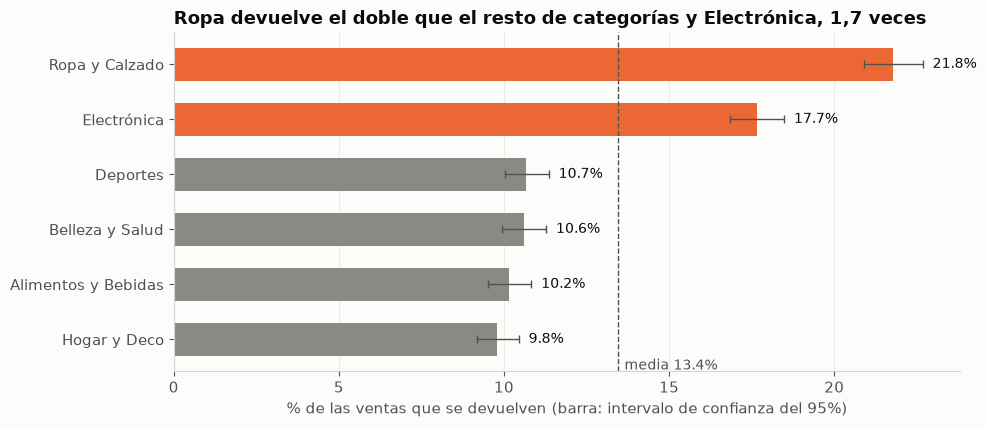

In [7]:
# Gráfico: tasa de devolución por categoría con IC 95%
t = tasas("categoria").sort_values("tasa %")
lo, hi = (np.asarray(x) for x in proportion_confint(t.devueltas, t.ventas, method="wilson"))
y = np.arange(len(t))
alta = t.index.isin(["Ropa_y_Calzado", "Electrónica"])
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.barh(y, t["tasa %"], color=np.where(alta, NARANJA, GRIS), height=0.6)
ax.errorbar(t["tasa %"], y, xerr=[t["tasa %"] - 100 * lo, 100 * hi - t["tasa %"]], fmt="none", ecolor=TEXTO_2, capsize=3, lw=1)
ax.axvline(100 * tasa_global, color=TEXTO_2, ls="--", lw=1)
ax.text(100 * tasa_global + 0.2, -0.55, f"media {100 * tasa_global:.1f}%", color=TEXTO_2, fontsize=10)
for i, v in enumerate(t["tasa %"]):
    ax.text(100 * hi[i] + 0.3, i, f"{v:.1f}%", va="center", fontsize=10)
ax.set_yticks(y, [c.replace("_", " ") for c in t.index])
ax.set_xlabel("% de las ventas que se devuelven (barra: intervalo de confianza del 95%)")
ax.set_title("Ropa devuelve el doble que el resto de categorías y Electrónica, 1,7 veces")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "a3_devoluciones_categoria.png", dpi=150)
plt.show()

## 2. Quejas sin resolver: ¿los clientes compran menos después?

**Qué comparamos (A3.3):** para cada queja contamos las compras del cliente en los 90 días **antes** y en los 90 días **después**. Solo usamos quejas con 90 días de datos a cada lado.

**Por qué no basta con mirar el "después":** después de cualquier contacto con atención al cliente podría haber una caída normal (por ejemplo, porque el cliente acababa de comprar). Por eso comparamos el **cambio** de los clientes con quejas sin resolver con el **cambio** de los clientes con quejas resueltas (diferencia en diferencias). Si la queja sin resolver espanta al cliente, su caída debería ser mayor.

In [8]:
print("Contactos por tipo y resolución:")
print(pd.crosstab(crm.tipo, crm.resolucion, margins=True).to_string())
print("\nTiempo de respuesta (mediana, horas) por resolución:", crm.groupby("resolucion").tiempo_respuesta_hrs.median().to_dict())

V = 90
c = crm[((crm.fecha - trx.fecha.min()).dt.days >= V) & ((FIN - crm.fecha).dt.days >= V)].copy()
c = c[c.cliente_id.isin(cli.loc[~cli.sin_compras, "cliente_id"])]
pares = c[["interaccion_id", "cliente_id", "fecha"]].merge(trx[["cliente_id", "fecha", "monto_neto"]],
                                                           on="cliente_id", suffixes=("", "_compra"))
dias = (pares.fecha_compra - pares.fecha).dt.days
pares["antes"] = dias.between(-V, -1)
pares["despues"] = dias.between(1, V)
conteo = pares.groupby("interaccion_id").agg(compras_antes=("antes", "sum"), compras_despues=("despues", "sum"),
                                             gasto_antes=("monto_neto", lambda s: s[pares.loc[s.index, "antes"]].sum()),
                                             gasto_despues=("monto_neto", lambda s: s[pares.loc[s.index, "despues"]].sum()))
c = c.join(conteo, on="interaccion_id").merge(cli[["cliente_id", "segmento"]], on="cliente_id")
c["cambio"] = c.compras_despues - c.compras_antes
q = c[c.tipo == "queja"]

orden = ["resuelto", "parcialmente_resuelto", "escalado", "sin_resolver"]
r = q.groupby("resolucion")[["compras_antes", "compras_despues", "cambio", "gasto_antes", "gasto_despues"]].mean().reindex(orden)
r.insert(0, "quejas", q.resolucion.value_counts())
print(f"\nQuejas con 90 días de datos a cada lado: {len(q)}. Promedio por queja:")
print(r.round(2).to_string())

Contactos por tipo y resolución:
resolucion       escalado  parcialmente_resuelto  resuelto  sin_resolver   All
tipo                                                                          
consulta              139                    320       821           216  1496
felicitacion           26                     49       122            36   233
queja                 471                    306       805           499  2081
soporte_tecnico        63                    182       483           146   874
All                   699                    857      2231           897  4684

Tiempo de respuesta (mediana, horas) por resolución: {'escalado': 11.5, 'parcialmente_resuelto': 11.7, 'resuelto': 12.3, 'sin_resolver': 12.2}



Quejas con 90 días de datos a cada lado: 1517. Promedio por queja:
                       quejas  compras_antes  compras_despues  cambio  gasto_antes  gasto_despues
resolucion                                                                                       
resuelto                  583           0.97             0.95   -0.02       312.18         341.77
parcialmente_resuelto     221           1.02             0.87   -0.15       345.28         303.26
escalado                  340           0.96             0.98    0.01       323.26         352.65
sin_resolver              373           0.98             0.92   -0.06       347.27         315.11


In [9]:
# Diferencia en diferencias con IC: cambio de cada grupo menos el cambio de las resueltas.
# Bootstrap por cliente (un cliente puede tener varias quejas).
def did(df):
    m = df.groupby("resolucion").cambio.mean()
    return m.reindex(orden[1:]) - m["resuelto"]

clientes_q = q.cliente_id.unique()
por_cliente = {k: g for k, g in q.groupby("cliente_id")}
boot = []
for _ in range(1000):
    muestra = pd.concat([por_cliente[k] for k in rng.choice(clientes_q, len(clientes_q))])
    boot.append(did(muestra))
boot = pd.DataFrame(boot)
res = pd.DataFrame({"diferencia": did(q), "IC 2,5%": boot.quantile(0.025), "IC 97,5%": boot.quantile(0.975)})
print("Cambio en compras (90 días) comparado con las quejas resueltas:")
print(res.round(3).to_string())

# Lo mismo con regresión, dejando fijo el segmento y con errores agrupados por cliente
modelo = smf.ols('cambio ~ C(resolucion, Treatment("resuelto")) + C(segmento)', data=q).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(q.cliente_id)[0]})
print()
print(modelo.summary2().tables[1].iloc[1:4, [0, 3, 4, 5]].round(3).to_string())

Cambio en compras (90 días) comparado con las quejas resueltas:
                       diferencia  IC 2,5%  IC 97,5%
resolucion                                          
parcialmente_resuelto      -0.125   -0.334     0.082
escalado                    0.039   -0.153     0.240
sin_resolver               -0.035   -0.211     0.132

                                                               Coef.  P>|z|  [0.025  0.975]
C(resolucion, Treatment("resuelto"))[T.escalado]               0.040  0.676  -0.148   0.228
C(resolucion, Treatment("resuelto"))[T.parcialmente_resuelto] -0.118  0.274  -0.330   0.093
C(resolucion, Treatment("resuelto"))[T.sin_resolver]          -0.034  0.698  -0.208   0.139


In [10]:
# Comprobaciones: ventana de 180 días (¿vuelve a comprar alguna vez?) y tiempo de respuesta
q180 = crm[(crm.tipo == "queja") & ((FIN - crm.fecha).dt.days >= 180) &
           crm.cliente_id.isin(cli.loc[~cli.sin_compras, "cliente_id"])].copy()
p = q180[["interaccion_id", "cliente_id", "fecha"]].merge(trx[["cliente_id", "fecha"]], on="cliente_id", suffixes=("", "_c"))
volvio = p[(p.fecha_c - p.fecha).dt.days.between(1, 180)].interaccion_id.unique()
q180["vuelve_180"] = q180.interaccion_id.isin(volvio)
t = q180.groupby("resolucion").vuelve_180.agg(["mean", "size"]).reindex(orden)
print("% de quejas tras las que el cliente vuelve a comprar en 180 días:")
print((t.assign(mean=100 * t["mean"])).round(1).to_string())
tabla = pd.crosstab(q180.resolucion == "sin_resolver", q180.vuelve_180)
print(f"Sin resolver contra el resto, prueba chi-cuadrado: p = {stats.chi2_contingency(tabla)[1]:.2f}")

m2 = smf.ols("cambio ~ np.log1p(tiempo_respuesta_hrs) + respuesta_atipica + C(segmento)", data=q).fit()
print("\nEfecto del tiempo de respuesta sobre el cambio en compras:")
print(m2.summary2().tables[1].loc[["respuesta_atipica[T.True]", "np.log1p(tiempo_respuesta_hrs)"], ["Coef.", "P>|t|"]].round(3).to_string())

todos = smf.ols('cambio ~ C(tipo, Treatment("consulta")) + C(segmento)', data=c).fit()
print("\nCambio en compras según el tipo de contacto (comparado con consultas):")
print(todos.summary2().tables[1].iloc[1:4, [0, 3]].round(3).to_string())

% de quejas tras las que el cliente vuelve a comprar en 180 días:
                       mean  size
resolucion                       
resuelto               70.8   599
parcialmente_resuelto  70.1   224
escalado               67.7   325
sin_resolver           67.0   348
Sin resolver contra el resto, prueba chi-cuadrado: p = 0.35

Efecto del tiempo de respuesta sobre el cambio en compras:
                                Coef.  P>|t|
respuesta_atipica[T.True]       0.113  0.480
np.log1p(tiempo_respuesta_hrs) -0.019  0.697

Cambio en compras según el tipo de contacto (comparado con consultas):
                                                   Coef.  P>|t|
C(tipo, Treatment("consulta"))[T.felicitacion]    -0.223  0.038
C(tipo, Treatment("consulta"))[T.queja]           -0.069  0.192
C(tipo, Treatment("consulta"))[T.soporte_tecnico] -0.079  0.231


In [11]:
# "No hay efecto" no es "efecto cero": ¿cuánto podría costar, como mucho, una queja sin resolver?
# Peor caso compatible con los datos: la cota baja del IC (compras perdidas por queja en 90 días), durante 6 meses
peor_90 = -res.loc["sin_resolver", "IC 2,5%"]
ticket = trx.monto_neto.mean()
quejas_sem = (crm.tipo.eq("queja") & crm.resolucion.eq("sin_resolver") & (crm.fecha >= "2024-01-01")).sum() / 2
tope_quejas = quejas_sem * peor_90 * 2 * ticket
print(f"Quejas sin resolver por semestre (2024): {quejas_sem:.0f}")
print(f"Peor caso compatible con el IC: {peor_90:.2f} compras menos en 90 días por queja → tope de {miles(tope_quejas)} u. m. en 6 meses")

Quejas sin resolver por semestre (2024): 130
Peor caso compatible con el IC: 0.21 compras menos en 90 días por queja → tope de 19.159 u. m. en 6 meses


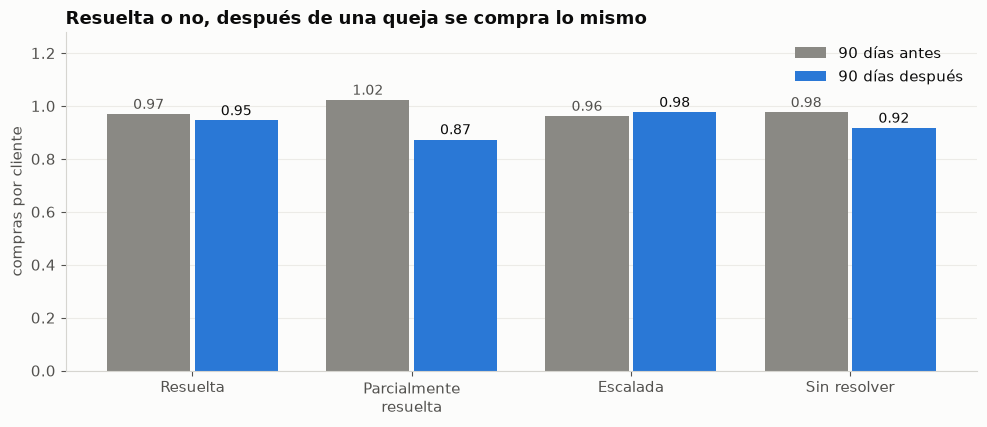

In [12]:
# Gráfico: compras antes y después de la queja, por resolución
etiquetas = {"resuelto": "Resuelta", "parcialmente_resuelto": "Parcialmente\nresuelta", "escalado": "Escalada", "sin_resolver": "Sin resolver"}
x = np.arange(len(orden))
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(x - 0.2, r.compras_antes, width=0.38, color=GRIS, label="90 días antes")
ax.bar(x + 0.2, r.compras_despues, width=0.38, color=AZUL, label="90 días después")
for i, (a, b) in enumerate(zip(r.compras_antes, r.compras_despues)):
    ax.text(i - 0.2, a + 0.02, f"{a:.2f}", ha="center", fontsize=10, color=TEXTO_2)
    ax.text(i + 0.2, b + 0.02, f"{b:.2f}", ha="center", fontsize=10)
ax.set_xticks(x, [etiquetas[o] for o in orden])
ax.set_ylabel("compras por cliente")
ax.set_title("Resuelta o no, después de una queja se compra lo mismo")
ax.legend(frameon=False, loc="upper right")
ax.set_ylim(0, r[["compras_antes", "compras_despues"]].max().max() * 1.25)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG / "a3_quejas.png", dpi=150)
plt.show()

## 3. Clientes en riesgo de fuga

**La medida de inactividad (A3.4):** los días que lleva el cliente sin comprar, al cierre de los datos (31-dic-2024). Un cliente está **en riesgo** si pasa de 180 días, el mismo umbral de A1.4 (9 de cada 10 veces que un cliente vuelve, lo hace antes de 162 días).

Pero "en riesgo" no es "perdido": en A1 vimos que el 52% de los que llegan a 180 días vuelve. Así que, para cada cliente en riesgo, estimamos **la probabilidad de que vuelva en los próximos 6 meses**. La sacamos de la historia: nos ponemos en una fecha pasada con 6 meses de datos por delante (30-jun-2024), agrupamos a los clientes y contamos qué parte volvió.

**Con qué agrupamos:** solo con lo que se sabía del cliente en esa fecha y de la forma más simple que funciona:
- si ya era **recurrente** (2 o más compras) o había comprado **una sola vez**;
- cuántos días llevaba sin comprar.

**No usamos el segmento del archivo**, porque se asignó contando las compras de los 24 meses, incluidas las posteriores a la foto (A1.4). Con él, "los Inactivo nunca vuelven" sale por definición.

Antes de usar la estimación la probamos: con la foto del 31-dic-2023 predecimos lo que pasó en el primer semestre de 2024 y lo comparamos con lo que pasó de verdad.

In [13]:
TRAMOS, NOMBRES = [-1, 90, 180, 270, 10_000], ["0-90", "91-180", "181-270", "más de 270"]
COMPRAS, GRUPOS = [-1, 0, 1, 3, 6, 10_000], ["ninguna", "1 compra", "2–3", "4–6", "7 o más"]
segmento = cli.set_index("cliente_id").segmento
H = pd.Timedelta(days=182)

def foto(corte):
    # Situación de cada cliente en la fecha de corte (solo con datos hasta ese día) y lo que hizo en los 6 meses siguientes
    h = trx[trx.fecha <= corte]
    f = h.groupby("cliente_id").agg(primera=("fecha", "min"), ultima=("fecha", "max"), gasto=("monto_neto", "sum"),
                                    n_compras=("transaccion_id", "size"))
    f["dias_sin_comprar"] = (corte - f.ultima).dt.days
    f["tramo"] = pd.cut(f.dias_sin_comprar, TRAMOS, labels=NOMBRES)
    f["recurrente"] = f.n_compras >= 2
    f["tipo"] = np.where(f.recurrente, "recurrente", "una sola compra")
    # compras en los 12 meses anteriores: solo para describir quién vuelve (gráfico)
    f["compras_12m"] = h[h.fecha > corte - pd.Timedelta(days=365)].groupby("cliente_id").size().reindex(f.index).fillna(0).astype(int)
    f["compras"] = pd.cut(f.compras_12m, COMPRAS, labels=GRUPOS)
    f["segmento"] = segmento.reindex(f.index)  # solo para describir
    # gasto por semestre desde su primera compra (mínimo un semestre)
    f["gasto_semestral"] = f.gasto / np.maximum(1, (corte - f.primera).dt.days / 182.5)
    futuro = trx[(trx.fecha > corte) & (trx.fecha <= corte + H)]
    f["vuelve"] = f.index.isin(futuro.cliente_id)
    f["gasto_6m"] = futuro.groupby("cliente_id").monto_neto.sum().reindex(f.index).fillna(0)
    return f

f23, f24, hoy = foto(pd.Timestamp("2023-12-31")), foto(pd.Timestamp("2024-06-30")), foto(FIN)

# El 52% de A1 cuenta cada vez que un cliente cumple 180 días sin comprar. En una foto, el grupo de
# "más de 180" incluye además a clientes que llevan mucho más tiempo, y esos vuelven menos.
for nombre, f in [("31-dic-2023", f23), ("30-jun-2024", f24)]:
    t = f.groupby("tramo", observed=True).vuelve.agg(["mean", "size"])
    print(f"Foto del {nombre}: % que vuelve en 6 meses según días sin comprar")
    print("  ", {k: f"{100 * v:.0f}% (n={n})" for k, (v, n) in t.iterrows()},
          f"| más de 180 días: {100 * f[f.dias_sin_comprar > 180].vuelve.mean():.0f}%")

Foto del 31-dic-2023: % que vuelve en 6 meses según días sin comprar
   {'0-90': '77% (n=3536.0)', '91-180': '62% (n=1433.0)', '181-270': '48% (n=805.0)', 'más de 270': '40% (n=547.0)'} | más de 180 días: 45%
Foto del 30-jun-2024: % que vuelve en 6 meses según días sin comprar
   {'0-90': '77% (n=3576.0)', '91-180': '61% (n=1411.0)', '181-270': '45% (n=814.0)', 'más de 270': '38% (n=1311.0)'} | más de 180 días: 41%


In [14]:
def tabla_retorno(f):
    # Proporción que volvió en 6 meses, por tipo de cliente (recurrente o no) y días sin comprar (clientes con más de 90 días)
    return f[f.dias_sin_comprar > 90].groupby(["tipo", "tramo"], observed=True).vuelve.agg(clientes="size", vuelve="mean")

def proyectar(f, t):
    f = f[f.dias_sin_comprar > DIAS_INACTIVO].drop(columns=["vuelve", "gasto_6m"]).join(t[["vuelve"]], on=["tipo", "tramo"])
    f["p_vuelve"] = f.vuelve.astype(float)
    assert f.p_vuelve.notna().all()
    # Si siguiera activo, gastaría lo mismo que venía gastando por semestre
    f["ingreso_perdido"] = (1 - f.p_vuelve) * f.gasto_semestral
    return f

# Prueba hacia atrás: con lo aprendido el 31-dic-2023, ¿acertamos el primer semestre de 2024?
prueba = proyectar(f24, tabla_retorno(f23))
prueba["volvio"] = f24.vuelve.reindex(prueba.index)
c = prueba.groupby("tipo").agg(clientes=("p_vuelve", "size"), vuelve_previsto=("p_vuelve", "mean"), vuelve_real=("volvio", "mean"))
c.loc["Total"] = [len(prueba), prueba.p_vuelve.mean(), prueba.volvio.mean()]
print("Prueba: clientes con más de 180 días sin comprar el 30-jun-2024")
print(c.round(3).to_string())

# Para comparar: el segmento del archivo "acierta" porque usa información posterior a la foto
seg_t = f23[f23.dias_sin_comprar > 90].groupby(["segmento", "tramo"], observed=True).vuelve.mean()
p_seg = [seg_t.get((s, tr), np.nan) for s, tr in zip(prueba.segmento, prueba.tramo)]
print(f"\nCon el segmento del archivo la prueba 'acierta' ({np.nanmean(p_seg):.0%} previsto) porque el segmento ya sabe quién volverá.")

Prueba: clientes con más de 180 días sin comprar el 30-jun-2024
                 clientes  vuelve_previsto  vuelve_real
tipo                                                   
recurrente          931.0            0.580        0.557
una sola compra    1194.0            0.383        0.293
Total              2125.0            0.469        0.409

Con el segmento del archivo la prueba 'acierta' (41% previsto) porque el segmento ya sabe quién volverá.


**Qué dice la prueba.** Con los clientes recurrentes, que son los que entran en la cifra principal, la estimación acierta casi del todo: 58% previsto contra 56% real. Con los de una sola compra se pasa. Esos clientes son cada vez más los que nunca vuelven, porque el archivo tiene 8.000 clientes fijos. Pero no entran en la cifra principal.

Probamos versiones más detalladas: por número de compras en toda la historia, por compras en los últimos 12 meses, con y sin calibración, y una regresión logística. Ninguna mejoraba la prueba con los recurrentes, y todas eran más difíciles de explicar. La versión anterior (compras en los últimos 12 meses, calibrada) daba 232.487 de fuga de recurrentes; esta da 227.341.

La versión con el segmento del archivo "acierta" (41% previsto, 41% real), pero solo porque el segmento usa información del futuro. Ese acierto no vale como prueba.

Ahora aplicamos lo aprendido con la foto más reciente (30-jun-2024) a los clientes en riesgo de hoy.

In [15]:
t24 = tabla_retorno(f24)
print("% que vuelve en 6 meses, por tipo de cliente y días sin comprar (foto del 30-jun-2024):")
print((100 * t24.vuelve.unstack()).round(0).to_string())
print("Clientes en cada casilla:")
print(t24.clientes.unstack().to_string())

riesgo = proyectar(hoy, t24)
riesgo["segmento_rfm"] = cli.set_index("cliente_id").segmento_rfm.reindex(riesgo.index)
assert (riesgo.segmento_rfm == "Inactivo").all()   # mismo umbral que A1.4
print(f"\nClientes en riesgo hoy (más de {DIAS_INACTIVO} días sin comprar): {len(riesgo)} "
      f"de {(~cli.sin_compras).sum()} con compras ({len(riesgo) / (~cli.sin_compras).sum():.0%})")
print(f"   de ellos, con una sola compra: {(~riesgo.recurrente).sum()}; recurrentes (2 o más): {riesgo.recurrente.sum()}")

# Para describir quién vuelve: % que vuelve en 6 meses entre los que llevaban más de 180 días, por compras en el último año
quien_vuelve = f24[f24.dias_sin_comprar > DIAS_INACTIVO].groupby("compras", observed=True).vuelve.agg(clientes="size", vuelve="mean")
print("\n% que vuelve en 6 meses (más de 180 días sin comprar el 30-jun-2024), por compras en los 12 meses anteriores:")
print(quien_vuelve.assign(vuelve=(100 * quien_vuelve.vuelve).round(0)).to_string())

% que vuelve en 6 meses, por tipo de cliente y días sin comprar (foto del 30-jun-2024):
tramo            91-180  181-270  más de 270
tipo                                        
recurrente         69.0     55.0        56.0
una sola compra    31.0     29.0        29.0
Clientes en cada casilla:
tramo            91-180  181-270  más de 270
tipo                                        
recurrente         1114      492         439
una sola compra     297      322         872

Clientes en riesgo hoy (más de 180 días sin comprar): 2647 de 7608 con compras (35%)
   de ellos, con una sola compra: 1259; recurrentes (2 o más): 1388

% que vuelve en 6 meses (más de 180 días sin comprar el 30-jun-2024), por compras en los 12 meses anteriores:
          clientes  vuelve
compras                   
ninguna        733    35.0
1 compra       996    38.0
2–3            335    52.0
4–6             57    91.0
7 o más          4   100.0


In [16]:
# Valor en riesgo, con IC bootstrap (se remuestrean los clientes de la foto del 30-jun-2024,
# se recalcula la tabla de retorno, y se remuestrean los clientes en riesgo)
def perdida(f_hist, f_hoy):
    r = proyectar(f_hoy, tabla_retorno(f_hist))
    return r[r.recurrente].ingreso_perdido.sum()

boot = []
for _ in range(300):
    fh = f24.sample(len(f24), replace=True, random_state=rng.integers(1e9)).reset_index(drop=True)
    fr = hoy.sample(len(hoy), replace=True, random_state=rng.integers(1e9)).reset_index(drop=True)
    boot.append(perdida(fh, fr))

rec = riesgo[riesgo.recurrente]
v = rec.groupby("segmento").agg(en_riesgo=("p_vuelve", "size"), p_vuelve=("p_vuelve", "mean"),
                                gasto_semestral=("gasto_semestral", "mean"), ingreso_perdido=("ingreso_perdido", "sum"))
v["% del total"] = 100 * v.ingreso_perdido / v.ingreso_perdido.sum()
v = v.sort_values("ingreso_perdido", ascending=False)
print("Clientes recurrentes en riesgo, por segmento del archivo (solo para describir):")
print(v.round({"p_vuelve": 2, "gasto_semestral": 0, "ingreso_perdido": 0, "% del total": 1}).to_string())
por_tipo = riesgo.groupby("tipo").agg(en_riesgo=("p_vuelve", "size"), p_vuelve=("p_vuelve", "mean"), ingreso_perdido=("ingreso_perdido", "sum"))
print("\nPor tipo de cliente:")
print(por_tipo.round({"p_vuelve": 2, "ingreso_perdido": 0}).to_string())
print("\nClientes con una sola compra en riesgo, por segmento del archivo:", riesgo[~riesgo.recurrente].segmento.value_counts().to_dict())

Clientes recurrentes en riesgo, por segmento del archivo (solo para describir):
            en_riesgo  p_vuelve  gasto_semestral  ingreso_perdido  % del total
segmento                                                                      
Esporádico       1077      0.56            309.0         146990.0         64.7
Frecuente         168      0.55            780.0          58437.0         25.7
Nuevo             132      0.56            271.0          15751.0          6.9
Premium            11      0.55           1248.0           6163.0          2.7

Por tipo de cliente:
                 en_riesgo  p_vuelve  ingreso_perdido
tipo                                                 
recurrente            1388      0.56         227341.0
una sola compra       1259      0.29         147002.0

Clientes con una sola compra en riesgo, por segmento del archivo: {'Inactivo': 654, 'Nuevo': 356, 'Esporádico': 247, 'Frecuente': 2}


**Resultado:**
- **Qué predice la vuelta:** si el cliente ya era recurrente, mucho más que cuánto tiempo lleva sin comprar. Entre los que llevaban más de 180 días sin comprar, vuelve en 6 meses el 38% de quienes compraron una vez en el último año y el 91% de quienes compraron de 4 a 6 veces (gráfico siguiente). Entre los recurrentes, vuelve el 69% si llevan 91–180 días sin comprar y alrededor del 55% si llevan más.
- **Hay 2.647 clientes en riesgo:** 1.259 que compraron una sola vez en toda su historia y 1.388 recurrentes (2 o más compras).
- **El segmento de mayor valor en riesgo es el Esporádico:** 1.077 clientes recurrentes en riesgo que dejarían de gastar 146.990 u. m. en 6 meses, el 65% de la fuga de clientes recurrentes.
- **Los "Inactivo" del archivo** son todos clientes de una sola compra (o ninguna). No los contamos como fuga recurrente.

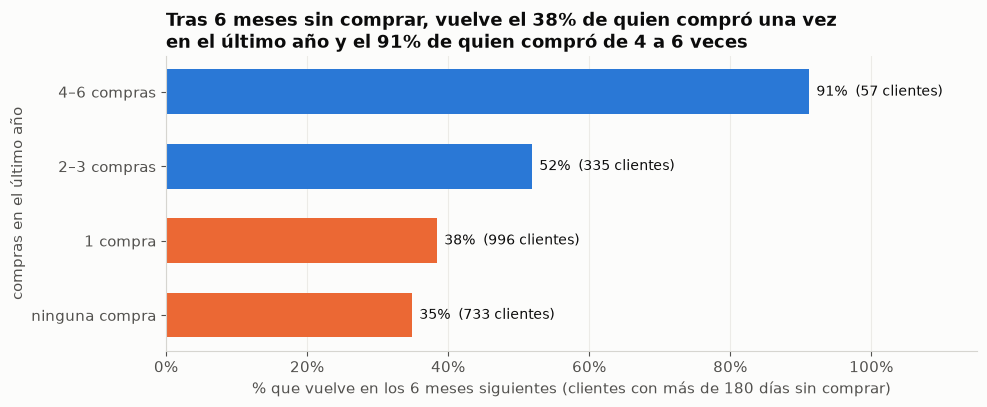

In [17]:
# Gráfico: % que vuelve en 6 meses entre los que llevaban más de 180 días sin comprar, por compras en el último año
q = quien_vuelve[quien_vuelve.clientes >= 30]          # grupos con suficientes clientes
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(q))
ax.barh(y, 100 * q.vuelve, color=[NARANJA if g in ("ninguna", "1 compra") else AZUL for g in q.index], height=0.6)
for i, (g, f) in enumerate(q.iterrows()):
    ax.text(100 * f.vuelve + 1, i, f"{100 * f.vuelve:.0f}%  ({int(f.clientes)} clientes)", va="center", fontsize=10)
ax.set_yticks(y, [{"ninguna": "ninguna compra", "1 compra": "1 compra"}.get(g, f"{g} compras") for g in q.index])
ax.set_ylabel("compras en el último año")
ax.set_xlim(0, 115)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel("% que vuelve en los 6 meses siguientes (clientes con más de 180 días sin comprar)")
uno, cuatro = 100 * q.loc["1 compra", "vuelve"], 100 * q.loc["4–6", "vuelve"]
ax.set_title(f"Tras 6 meses sin comprar, vuelve el {uno:.0f}% de quien compró una vez\nen el último año y el {cuatro:.0f}% de quien compró de 4 a 6 veces")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "a3_retorno_compras.png", dpi=150)
plt.show()

## 4. Impacto económico a 6 meses

**Cómo lo calculamos (A3.5):** separamos lo que tiene un responsable claro (clientes que se van, devoluciones por encima de lo normal) de lo que es un costo estable del negocio.

**La cifra principal (fugas identificadas):**
- **Clientes recurrentes en riesgo:** clientes con 2 o más compras que llevan más de 180 días sin comprar. Para cada uno, (1 − probabilidad de volver) × lo que venía gastando por semestre. Rango: IC 95% *bootstrap*.
- **Devoluciones de Ropa y Electrónica por encima de lo normal:** lo que devuelven por encima de la tasa de las otras cuatro categorías (A3.1). No lo llamamos "evitable": en Ropa una parte tiene causa (la talla), pero en Electrónica los datos no muestran por qué (A5.4).

**Aparte:**
- **Clientes con una sola compra:** no los contamos como fuga. Nunca fueron clientes recurrentes, así que su "gasto por semestre" no es un ritmo que se pierda. Damos la cifra como referencia.
- **Reembolsos totales:** el 13–14% de las ventas se devuelve desde siempre (A1). Es un costo estructural del negocio y no una fuga nueva. Lo damos en ingresos y en margen (con las dos versiones de A2.1).
- **Quejas sin resolver:** 0, porque no detectamos efecto. Damos el tope compatible con los datos (sección 2).
- **Descuentos:** no son una pérdida de ingresos, pero se llevan el 18,3% del margen (A2). Están en la tabla de pérdidas de A5, junto con estas.

Todas las cifras de devoluciones tienen base 2024 (el último año completo) y se expresan a 6 meses (la mitad del año). Es la misma base que usa A5.

In [18]:
# Fuga de clientes recurrentes, con IC bootstrap
churn = rec.ingreso_perdido.sum()
churn_lo, churn_hi = np.quantile(boot, [0.025, 0.975])
unica = riesgo[~riesgo.recurrente].ingreso_perdido.sum()
margen_pct = trx.margen_bruto.sum() / trx.monto_neto.sum()

# Devoluciones: año 2024, expresado a 6 meses
a24 = trx[trx.fecha.dt.year == 2024]
MEDIO = 0.5
dev_ingreso = a24.loc[a24.devuelta, "monto_neto"].sum() * MEDIO
dev_margen = (a24.margen_bruto - a24.margen_neto).sum() * MEDIO
dev_margen_prov = a24.loc[a24.devuelta, "margen_bruto"].sum() * MEDIO   # si el proveedor asume los defectuosos (A2.1)

# Ropa y Electrónica por encima de la tasa de las otras categorías, 2024
DOS = ["Ropa_y_Calzado", "Electrónica"]
u = a24[a24.categoria.isin(DOS)]
resto_u = a24[~a24.categoria.isin(DOS)].devuelta.mean()
fraccion = 1 - resto_u / u.groupby("categoria").devuelta.mean()
exc_ingreso = MEDIO * sum(u.loc[u.devuelta & (u.categoria == c), "monto_neto"].sum() * fraccion[c] for c in fraccion.index)
exc_margen = MEDIO * sum((u.margen_bruto - u.margen_neto)[u.categoria == c].sum() * fraccion[c] for c in fraccion.index)
exc_margen_prov = MEDIO * sum(u.loc[u.devuelta & (u.categoria == c), "margen_bruto"].sum() * fraccion[c] for c in fraccion.index)

ventas_sem = a24.monto_neto.sum() * MEDIO
resumen = pd.DataFrame([
    ["Clientes recurrentes en riesgo que no vuelven", churn, churn_lo, churn_hi, churn_lo * margen_pct, churn_hi * margen_pct],
    ["Devoluciones por encima de lo normal (Ropa y Electrónica)", exc_ingreso, exc_ingreso, exc_ingreso, exc_margen_prov, exc_margen],
    ["Fugas identificadas (cifra principal)", churn + exc_ingreso, churn_lo + exc_ingreso, churn_hi + exc_ingreso,
     churn_lo * margen_pct + exc_margen_prov, churn_hi * margen_pct + exc_margen],
    ["Aparte: clientes con una sola compra", unica, np.nan, np.nan, unica * margen_pct, np.nan],
    ["Aparte: reembolsos totales (costo estructural)", dev_ingreso, np.nan, np.nan, dev_margen_prov, dev_margen],
    ["Aparte: quejas sin resolver (tope)", 0, 0, tope_quejas, 0, tope_quejas * margen_pct],
], columns=["fuga", "ingresos", "desde", "hasta", "margen (bajo)", "margen (alto)"]).set_index("fuga")
resumen["% de las ventas del semestre"] = 100 * resumen.ingresos / ventas_sem
print(f"Ventas de medio año (base 2024): {miles(ventas_sem)}")
print(resumen.round(0).assign(**{"% de las ventas del semestre": resumen["% de las ventas del semestre"].round(1)}).to_string())
assert abs(resumen.loc["Fugas identificadas (cifra principal)", "ingresos"] - churn - exc_ingreso) < 1
print(f"\nMargen de los clientes en riesgo calculado con el margen bruto medio ({margen_pct:.1%}).")
print("Margen: en devoluciones, bajo = el proveedor asume los defectuosos y alto = la empresa los pierde (A2.1);"
      " en clientes, el IC 95%.")

Ventas de medio año (base 2024): 4.342.290
                                                           ingresos     desde     hasta  margen (bajo)  margen (alto)  % de las ventas del semestre
fuga                                                                                                                                               
Clientes recurrentes en riesgo que no vuelven              227341.0  205625.0  247909.0        50958.0        61437.0                           5.2
Devoluciones por encima de lo normal (Ropa y Electrónica)  185082.0  185082.0  185082.0        35233.0        80824.0                           4.3
Fugas identificadas (cifra principal)                      412423.0  390707.0  432992.0        86191.0       142261.0                           9.5
Aparte: clientes con una sola compra                       147002.0       NaN       NaN        36430.0            NaN                           3.4
Aparte: reembolsos totales (costo estructural)             645361.0  

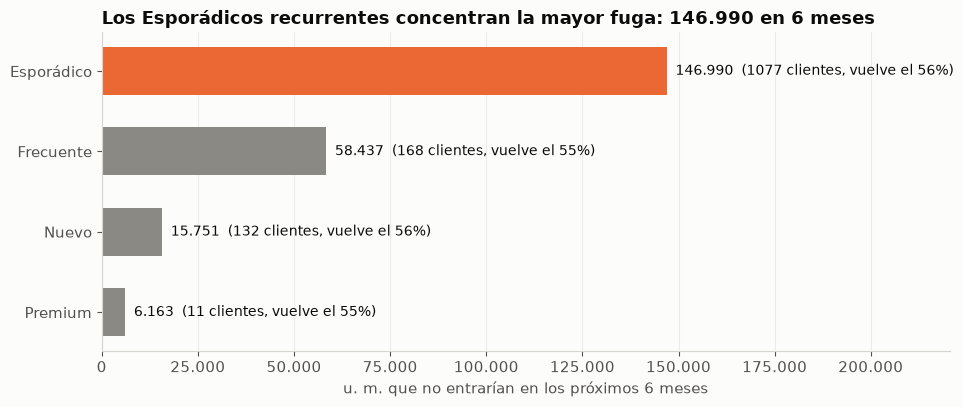

In [19]:
# Gráfico: ingresos perdidos a 6 meses por segmento del archivo (clientes recurrentes en riesgo)
v2 = v.sort_values("ingreso_perdido")
y = np.arange(len(v2))
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(y, v2.ingreso_perdido, color=[NARANJA if s == v2.ingreso_perdido.idxmax() else GRIS for s in v2.index], height=0.6)
for i, (s, fila) in enumerate(v2.iterrows()):
    ax.text(fila.ingreso_perdido + v2.ingreso_perdido.max() * 0.015, i,
            f"{miles(fila.ingreso_perdido)}  ({int(fila.en_riesgo)} clientes, vuelve el {100 * fila.p_vuelve:.0f}%)", va="center", fontsize=10)
ax.set_yticks(y, v2.index)
ax.set_xlim(0, v2.ingreso_perdido.max() * 1.5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: miles(x)))
ax.set_xlabel("u. m. que no entrarían en los próximos 6 meses")
top = v.ingreso_perdido.idxmax()
ax.set_title(f"Los {top}s recurrentes concentran la mayor fuga: {miles(v.ingreso_perdido.max())} en 6 meses")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "a3_fuga_segmento.png", dpi=150)
plt.show()

## 5. Resumen de A3

**Devoluciones**
- Se devuelve el 13,4% de las ventas, y la tasa no cambia entre semestres (de 13,3% a 13,6%).
- **Solo dos categorías se salen de lo normal:** Ropa y Calzado (21,8%) y Electrónica (17,7%). Las otras cuatro devuelven entre 9,8% y 10,7%. El segmento, el canal y el medio de pago no cambian la tasa.
- No hay productos problemáticos sueltos: 51 productos parecen anómalos frente a la media global, pero ninguno lo es frente a su propia categoría. El problema es de la categoría completa.
- **Los motivos:** Ropa devuelve de más por **talla incorrecta** (un motivo que solo existe en ropa) y porque todos los motivos son más frecuentes. En Electrónica, el reparto de motivos es el mismo que en el resto de categorías (39% "no cumple expectativas", 27,5% defectuoso): devuelve más por todos los motivos a la vez, no por uno concreto.
- **No hay devolvedores habituales:** 793 clientes tienen 3 o más devoluciones, y por azar se esperarían 785. Quien devuelve mucho es porque compra mucho. Solo 5 clientes repiten fraude.

**Quejas sin resolver**
- **No detectamos que los clientes con quejas sin resolver compren menos.** En los 90 días siguientes a la queja compran 0,92 veces (antes, 0,98). Los de quejas resueltas pasan de 0,97 a 0,95. La diferencia (−0,03 compras) cabe en lo que puede ser azar (IC 95%: −0,21 a +0,13).
- "No detectable" no es "cero". El intervalo deja pasar una caída de hasta 0,21 compras en 90 días por queja. Con unas 130 quejas sin resolver por semestre, eso costaría como mucho 19.159 u. m. en 6 meses. Es poco comparado con las otras fugas.
- Tampoco a 180 días: vuelve a comprar el 67% de los que tuvieron una queja sin resolver y el 71% de los que la tuvieron resuelta (p = 0,35). Ni el tiempo de respuesta ni las respuestas muy lentas cambian nada.

**Clientes en riesgo**
- **Medida:** días sin comprar al 31-dic-2024. En riesgo = más de 180 días. Hay 2.647 clientes en riesgo, el 35% de los que alguna vez compraron: 1.388 recurrentes y 1.259 de una sola compra.
- **Probabilidad de volver:** se estima solo con datos conocidos en la fecha de corte (si el cliente ya era recurrente y cuántos días llevaba sin comprar), no con el segmento del archivo. Un recurrente en riesgo vuelve en 6 meses alrededor del 55% de las veces; uno de una sola compra, el 29%.
- **Prueba hacia atrás:** con los recurrentes, 58% previsto contra 56% real. Versiones más complejas no la mejoraban.
- **El segmento de mayor valor en riesgo es el Esporádico:** 1.077 clientes recurrentes en riesgo que dejarían de gastar 146.990 u. m. en 6 meses, el 65% de la fuga de clientes recurrentes.

**Impacto económico a 6 meses** (base 2024; medio año de ventas: 4.342.290 u. m.)
- **Fugas identificadas, la cifra principal: 412.423 u. m. (rango 390.707 a 432.992), el 9,5% de las ventas de un semestre.** Se compone de:
  - Clientes recurrentes que no vuelven: 227.341 (205.625 a 247.909).
  - Devoluciones de Ropa y Electrónica por encima de lo normal: 185.082 en ingresos; en margen, de 35.233 a 80.824 según quién asuma los defectuosos. No lo llamamos "evitable": en Electrónica no se ve la causa.
- **Aparte, como referencia:**
  - Clientes con una sola compra en riesgo: 147.002. No es una fuga de ingresos recurrentes.
  - Reembolsos totales: 645.361 (14,9% de las ventas). Es un costo estructural y estable, no una fuga nueva.
  - Quejas sin resolver: no detectable, con un tope de 19.159.

**Títulos de gráfico candidatos para A5**
- "Ropa devuelve el doble que el resto de categorías y Electrónica, 1,7 veces" (`figures/a3_devoluciones_categoria.png`)
- "Resuelta o no, después de una queja se compra lo mismo" (`figures/a3_quejas.png`)
- "Tras 6 meses sin comprar, vuelve el 38% de quien compró una vez en el último año y el 91% de quien compró de 4 a 6 veces" (`figures/a3_retorno_compras.png`)
- "Los Esporádicos recurrentes concentran la mayor fuga: 146.990 en 6 meses" (`figures/a3_fuga_segmento.png`)